## **Задание**

1. На основе первого примера создать 4 набора шариков разных цветов другой палитры, которые не пересекаются и распределить их.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

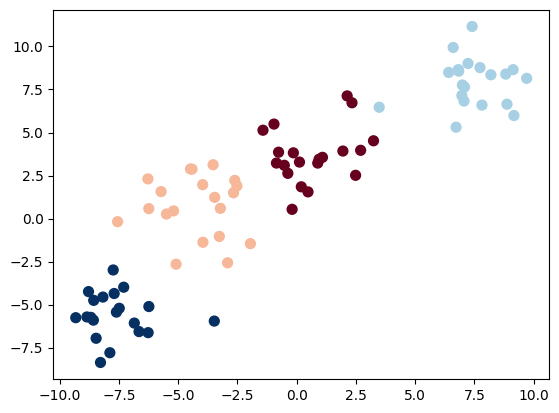

In [2]:
from sklearn.datasets import make_blobs
X, y = make_blobs(80, 2, centers=4, random_state=3, cluster_std=1.5)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='RdBu');

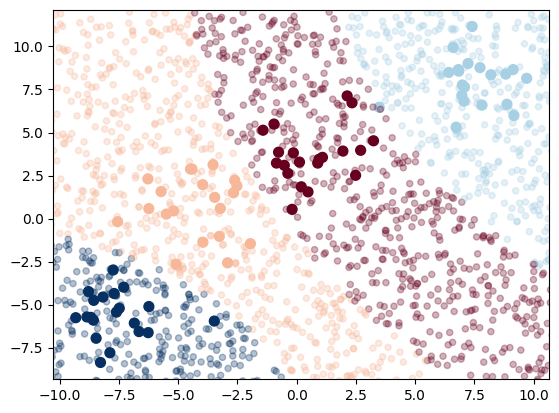

In [3]:
from sklearn.naive_bayes import GaussianNB
model = GaussianNB()

model.fit(X, y)

rng = np.random.RandomState(0)
Xnew = Xnew = [-11, -12] + [22, 24] * rng.rand(2000, 2)
ynew = model.predict(Xnew)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='RdBu')
lim = plt.axis()
plt.scatter(Xnew[:, 0], Xnew[:, 1], c=ynew, s=20, cmap='RdBu', alpha=0.3)
plt.axis(lim);

2. Создать базу данных с описанием фильмов и тегами жанров. Используя полиномиальный наивный байесовский классификатор обучить эти данные.

In [5]:
import pandas as pd
# Ссылка на google sheets "Kinopoisk_dataset": https://docs.google.com/spreadsheets/d/1VecQzJi6s6sJd863CtGsdEAThHwp8FwCxo-q65qKo3E

url = r'https://docs.google.com/spreadsheets/d/1VecQzJi6s6sJd863CtGsdEAThHwp8FwCxo-q65qKo3E/export?format=csv'
data = pd.read_csv(url, index_col='rank')

df = pd.DataFrame(data)

In [6]:
from sklearn.model_selection import train_test_split

# В качестве признака берем описание
X = df['description']

# Таргет — жанр
y = df['genre']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print(y_train)

rank
83     фантастика
68        триллер
44        комедия
100    фантастика
58        триллер
          ...    
80     фантастика
96     фантастика
75        триллер
5          боевик
49        комедия
Name: genre, Length: 80, dtype: object


In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline

model = make_pipeline(TfidfVectorizer(), MultinomialNB())
model.fit(X_train, y_train)
labels = model.predict(X_test)

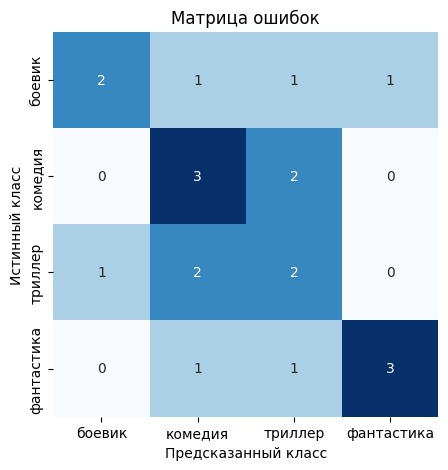

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Получаем предсказания модели (если еще не получены)
y_pred = model.predict(X_test)

# 2. Получаем упорядоченный список классов из обученной модели
classes = model.classes_

# 3. Строим матрицу ошибок
mat = confusion_matrix(y_test, y_pred, labels=classes)
# mat = confusion_matrix(y_train, y_pred, labels=classes)
# 4. Визуализируем (строки — True, столбцы — Predicted)
plt.figure(figsize=(6, 5))
sns.heatmap(
    mat,
    square=True,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=False,
    xticklabels=classes,
    yticklabels=classes
)
plt.xlabel('Предсказанный класс')
plt.ylabel('Истинный класс')
plt.title('Матрица ошибок')
plt.show()

In [11]:
def predict_category(text, model):
    return model.predict([text])[0]

print(predict_category("Экипаж космического корабля отправляется к далекий космос ", model))

фантастика


In [10]:
examples = {
    'комедия': (
        'Двое соседей случайно меняются чемоданами перед отпуском. '
        'Один приезжает на пляж с костюмом ростовой курицы, '
        'а другой приходит на собеседование с ластами и надувным кругом.'
    ),
    'боевик': (
        'Вооружённые наёмники захватывают порт и берут рабочих '
        'в заложники. Бывший спецназовец проникает на территорию, '
        'чтобы освободить брата и остановить вывоз оружия.'
    ),
    'фантастика': (
        'На спутнике далёкой планеты исследователи находят устройство, '
        'которое передаёт сообщения из будущего. Получив предупреждение '
        'о гибели станции, экипаж пытается изменить ход событий.'
    ),
    'триллер': (
        'Женщина получает фотографии своей квартиры, сделанные '
        'в её отсутствие. Полиция не находит следов проникновения, '
        'а на следующем снимке она видит себя спящей.'
    )
}

for expected, description in examples.items():
    predicted = predict_category(description, model)
    print(f'Предсказанный: \t {predicted}')
    print(f'Ожидаемый жанр:\t {expected}  \nОписание: \t {description}\n')


Предсказанный: 	 комедия
Ожидаемый жанр:	 комедия  
Описание: 	 Двое соседей случайно меняются чемоданами перед отпуском. Один приезжает на пляж с костюмом ростовой курицы, а другой приходит на собеседование с ластами и надувным кругом.

Предсказанный: 	 боевик
Ожидаемый жанр:	 боевик  
Описание: 	 Вооружённые наёмники захватывают порт и берут рабочих в заложники. Бывший спецназовец проникает на территорию, чтобы освободить брата и остановить вывоз оружия.

Предсказанный: 	 фантастика
Ожидаемый жанр:	 фантастика  
Описание: 	 На спутнике далёкой планеты исследователи находят устройство, которое передаёт сообщения из будущего. Получив предупреждение о гибели станции, экипаж пытается изменить ход событий.

Предсказанный: 	 триллер
Ожидаемый жанр:	 триллер  
Описание: 	 Женщина получает фотографии своей квартиры, сделанные в её отсутствие. Полиция не находит следов проникновения, а на следующем снимке она видит себя спящей.

